# Liquidity Absorption 10 — The **unselected** level universe

**Purpose:** follow every observable reference level from the time it can first be known, whether it gets no valid touch, one touch, or a valid second-touch A02 signal. This fixes the selected-only denominator in Module 09. No new trade signals or profitable strategy claim.

The level universe is the **last active reference in each original A02 stream**, not every historical pivot ever observed. Confirmation delays: pivot `source_close + 10m`; prior-day extreme: next UTC midnight. Exact replay against all 452 frozen A02 candidate signals is mandatory; a mismatch aborts output publication. We do **not** reparameterize A02 or include any post-signal P&L.

Censored references (replaced or unavailable before a horizon) are explicitly reported. First-touch spells distinguish second confirmation, invalidation, reference replacement, retest expiry, and archive-end censoring. All touches are **one-minute rejection-candle closes**, not exact exchange print timestamps.


In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display, Image
REPO=Path.cwd().resolve()
while REPO!=REPO.parent and not (REPO/'src'/'data_engineering').is_dir():
    REPO=REPO.parent
assert (REPO/'src'/'data_engineering').is_dir(), 'Open Jupyter from within the repository'
if str(REPO) not in sys.path: sys.path.insert(0,str(REPO))
from src.data_engineering.modeling.liquidity_absorption_stage_a import binance_root
from src.data_engineering.modeling.liquidity_absorption_stage_a10 import VERSION,Config,run
assert VERSION=='LA-LEVEL-UNIVERSE-10-0.1.0', 'git pull and restart kernel'
for pattern in ('test_liquidity_absorption_stage_a10.py','test_liquidity_absorption_stage_a10_notebook.py'):
    x=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-p',pattern,'-q'],cwd=REPO,text=True,capture_output=True)
    print(pattern, x.stdout[-500:], x.stderr[-2500:])
    assert x.returncode==0, f'Regression tests failed: {pattern}'
FUTURES_ROOT=binance_root(REPO)
OUT=REPO/'notebooks'/'Liquidity_Absorption'/'10'
print('A10',VERSION,'Data:',FUTURES_ROOT,'Output:',OUT)


test_liquidity_absorption_stage_a10.py  ----------------------------------------------------------------------
Ran 16 tests in 0.611s

OK

test_liquidity_absorption_stage_a10_notebook.py  ----------------------------------------------------------------------
Ran 1 test in 0.003s

OK

A10 LA-LEVEL-UNIVERSE-10-0.1.0 Data: D:\MarketData\Binance Output: D:\Projects\deribit_market_data\notebooks\Liquidity_Absorption\10


## 1. Reconstruct all observed level episodes; enforce exact A02 signal replay

The engine replays the 4 stream state machines using the original A02 config and Binance UM 1m price tape. No new parameters are fitted. A mismatch with the 452 saved A02 signals is a fatal error.


In [2]:
decision=run(REPO,FUTURES_ROOT,OUT,Config())
display(pd.Series(decision).to_frame('value'))
assert decision['exact_signal_replay'] and decision['original_A02_signals']==452


,value
version,LA-LEVEL-UNIVERSE-10-0.1.0
status,EXPLORATORY_SELECTED_VS_UNSELECTED_LEVEL_UNIVE...
original_A02_signals,452
replayed_signals,452
exact_signal_replay,True
level_episode_rows_all_including_warmup,15045
primary_new_level_episodes,14577
primary_classification_counts,"{'NO_VALID_TOUCH': 11137, 'FIRST_TOUCH_NO_SIGN..."
primary_censored_at_end,7
first_touch_spells_including_warmup,3967


## 2. Which levels are untouched, first-touched, or twice-touched?

**Do not use the signal-conditioned sample as the denominator.** The population includes every *observable and currently selected A02 reference episode*. A replaced reference is no longer the active A02 level; its later price reactions are not assigned to that earlier episode. Prior-day and pivot families are kept separate.


In [3]:
levels=pd.read_csv(OUT/'10_level_episodes.csv')
groups=pd.read_csv(OUT/'10_episodes_by_type.csv')
print('All vs primary sample:')
display(levels.groupby(['symbol','level_type','primary_newly_observable','classification']).size().rename('count').reset_index())
print('Primary rates, including no-touch episodes:')
display(groups.sort_values(['symbol','level_type','side','classification']).round(3))


All vs primary sample:


,symbol,level_type,primary_newly_observable,classification,count
0,BTCUSDT,pivot_5m,False,FIRST_TOUCH_NO_SIGNAL,50
1,BTCUSDT,pivot_5m,False,NO_VALID_TOUCH,176
2,BTCUSDT,pivot_5m,True,FIRST_TOUCH_NO_SIGNAL,1431
3,BTCUSDT,pivot_5m,True,NO_VALID_TOUCH,5420
4,BTCUSDT,pivot_5m,True,SECOND_TOUCH_SIGNAL,176
5,BTCUSDT,prior_day,False,FIRST_TOUCH_NO_SIGNAL,2
6,BTCUSDT,prior_day,False,NO_VALID_TOUCH,2
7,BTCUSDT,prior_day,True,FIRST_TOUCH_NO_SIGNAL,36
8,BTCUSDT,prior_day,True,NO_VALID_TOUCH,124
9,BTCUSDT,prior_day,True,SECOND_TOUCH_SIGNAL,24


Primary rates, including no-touch episodes:


,symbol,level_type,side,classification,n,median_observed_minutes,median_time_to_first_touch,median_touch_count,median_invalidations
0,BTCUSDT,pivot_5m,resistance,FIRST_TOUCH_NO_SIGNAL,721,30.0,13.0,1.0,0.0
1,BTCUSDT,pivot_5m,resistance,NO_VALID_TOUCH,2735,30.0,NaN,0.0,0.0
2,BTCUSDT,pivot_5m,resistance,SECOND_TOUCH_SIGNAL,91,35.0,12.0,2.0,0.0
3,BTCUSDT,pivot_5m,support,FIRST_TOUCH_NO_SIGNAL,710,30.0,13.0,1.0,1.0
4,BTCUSDT,pivot_5m,support,NO_VALID_TOUCH,2685,35.0,NaN,0.0,0.0
5,BTCUSDT,pivot_5m,support,SECOND_TOUCH_SIGNAL,85,35.0,9.0,2.0,0.0
6,BTCUSDT,prior_day,resistance,FIRST_TOUCH_NO_SIGNAL,18,1440.0,444.0,2.0,113.5
7,BTCUSDT,prior_day,resistance,NO_VALID_TOUCH,59,1440.0,NaN,0.0,0.0
8,BTCUSDT,prior_day,resistance,SECOND_TOUCH_SIGNAL,15,1440.0,643.0,7.0,601.0
9,BTCUSDT,prior_day,support,FIRST_TOUCH_NO_SIGNAL,18,1440.0,880.5,2.0,247.5


## 3. Competing first-touch and second-touch outcomes by horizon

The first-touch table labels episodes whose exposure ended before a given horizon as **censored**, rather than declaring them failures. The second-touch table uses one row per valid first-touch *spell*: invalidation/replacement/expiry is a competing event; an archive-end open spell is right-censored. These simple fractions are **observed proportions, not Kaplan–Meier/Aalen–Johansen survival estimates**. Do not compare long and short reference lifetimes naively.


In [4]:
first=pd.read_csv(OUT/'10_first_touch_incidence.csv')
second=pd.read_csv(OUT/'10_second_touch_incidence.csv')
spells=pd.read_csv(OUT/'10_first_touch_spells.csv')
display(first.sort_values(['symbol','level_type','side','horizon_min']).round(3))
display(second.sort_values(['symbol','level_type','side','horizon_min']).round(3))
print('Touch-spell terminal reasons, not synonymous with trading failures:')
display(spells.groupby(['symbol','level_type','end_reason']).size().rename('n').reset_index())


,symbol,level_type,side,horizon_min,n_original_new_episodes,n_first_touch_known,n_first_touch_by_h,fraction_first_touch_by_h,n_censored_before_h,n_episodes_with_any_signal
0,BTCUSDT,pivot_5m,resistance,5,3547,3547,194,0.055,0,91
1,BTCUSDT,pivot_5m,resistance,15,3547,3236,455,0.141,311,91
2,BTCUSDT,pivot_5m,resistance,30,3547,2167,660,0.305,1380,91
3,BTCUSDT,pivot_5m,resistance,60,3547,1103,794,0.720,2444,91
4,BTCUSDT,pivot_5m,resistance,90,3547,873,808,0.926,2674,91
5,BTCUSDT,pivot_5m,support,5,3480,3480,239,0.069,0,85
6,BTCUSDT,pivot_5m,support,15,3480,3199,469,0.147,281,85
7,BTCUSDT,pivot_5m,support,30,3480,2214,661,0.299,1266,85
8,BTCUSDT,pivot_5m,support,60,3480,1128,773,0.685,2352,85
9,BTCUSDT,pivot_5m,support,90,3480,857,792,0.924,2623,85


,symbol,level_type,side,horizon_min,n_spells,n_assessable,n_second_by_h,n_competing_by_h,n_right_censored_before_h,observed_second_incidence_by_h
0,BTCUSDT,pivot_5m,resistance,5,834,834,26,245,0,0.031
1,BTCUSDT,pivot_5m,resistance,15,834,834,72,673,0,0.086
2,BTCUSDT,pivot_5m,resistance,30,834,834,83,734,0,0.100
3,BTCUSDT,pivot_5m,resistance,60,834,834,87,746,0,0.104
4,BTCUSDT,pivot_5m,resistance,90,834,834,87,747,0,0.104
5,BTCUSDT,pivot_5m,support,5,816,816,17,266,0,0.021
6,BTCUSDT,pivot_5m,support,15,816,816,71,647,0,0.087
7,BTCUSDT,pivot_5m,support,30,816,816,81,719,0,0.099
8,BTCUSDT,pivot_5m,support,60,816,816,83,733,0,0.102
9,BTCUSDT,pivot_5m,support,90,816,816,83,733,0,0.102


Touch-spell terminal reasons, not synonymous with trading failures:


,symbol,level_type,end_reason,n
0,BTCUSDT,pivot_5m,INVALIDATED,614
1,BTCUSDT,pivot_5m,REPLACED_BY_NEW_REFERENCE,970
2,BTCUSDT,pivot_5m,RETEST_GAP_EXPIRED,1
3,BTCUSDT,pivot_5m,SECOND_TOUCH_SIGNAL,176
4,BTCUSDT,prior_day,INVALIDATED,103
5,BTCUSDT,prior_day,REPLACED_BY_NEW_REFERENCE,1
6,BTCUSDT,prior_day,RETEST_GAP_EXPIRED,31
7,BTCUSDT,prior_day,SECOND_TOUCH_SIGNAL,36
8,ETHUSDT,pivot_5m,INVALIDATED,735
9,ETHUSDT,pivot_5m,REPLACED_BY_NEW_REFERENCE,943


## 4. Descriptive plots: full denominator and time to first/second touch

Outcome denominators are per level episode, not the 452 selected signals. The two panels include separate BTC/ETH and pivot/prior-day populations.


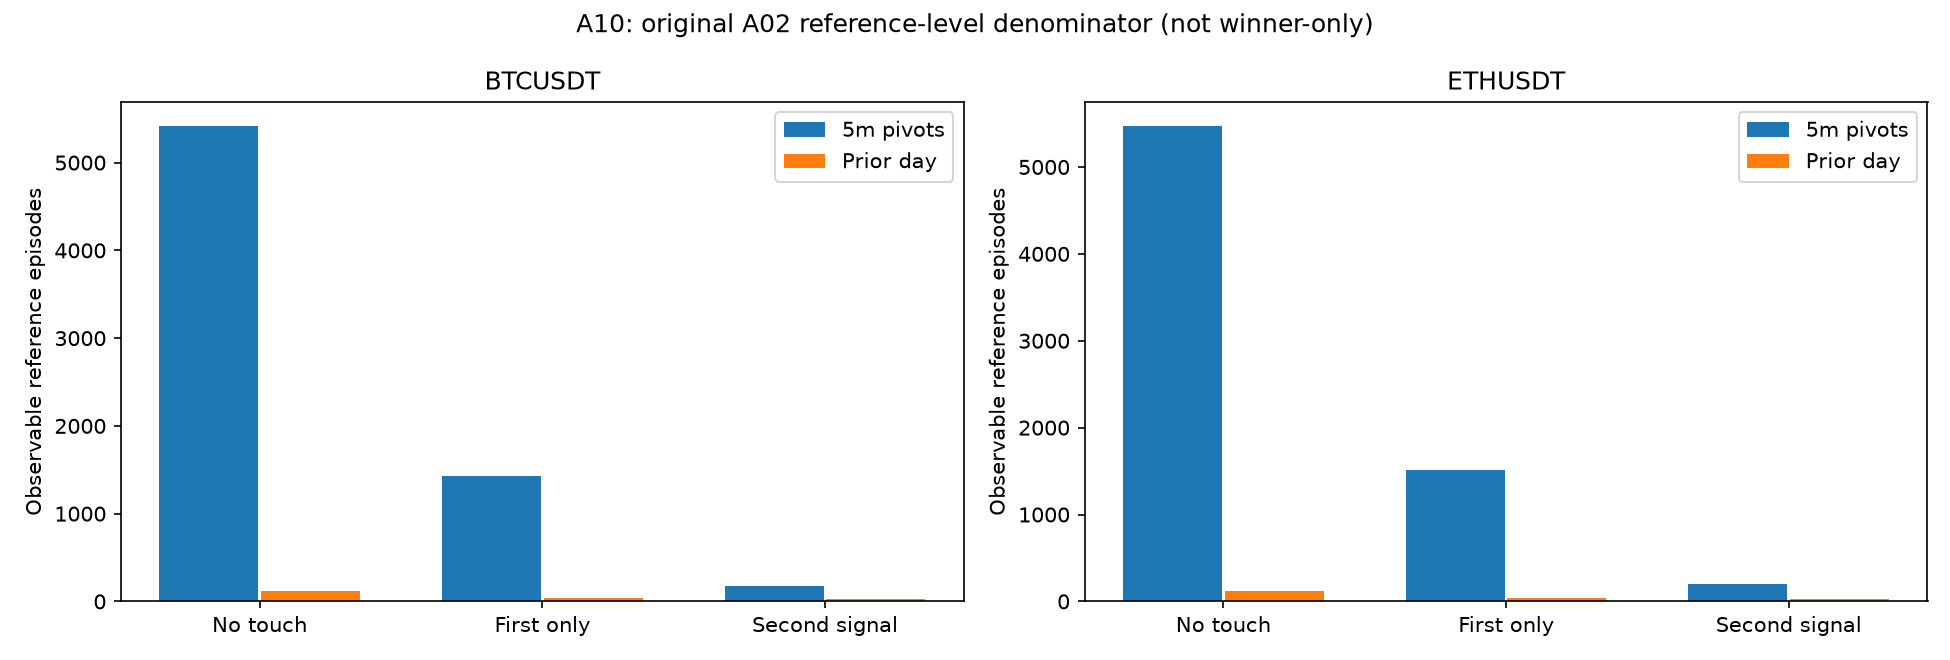

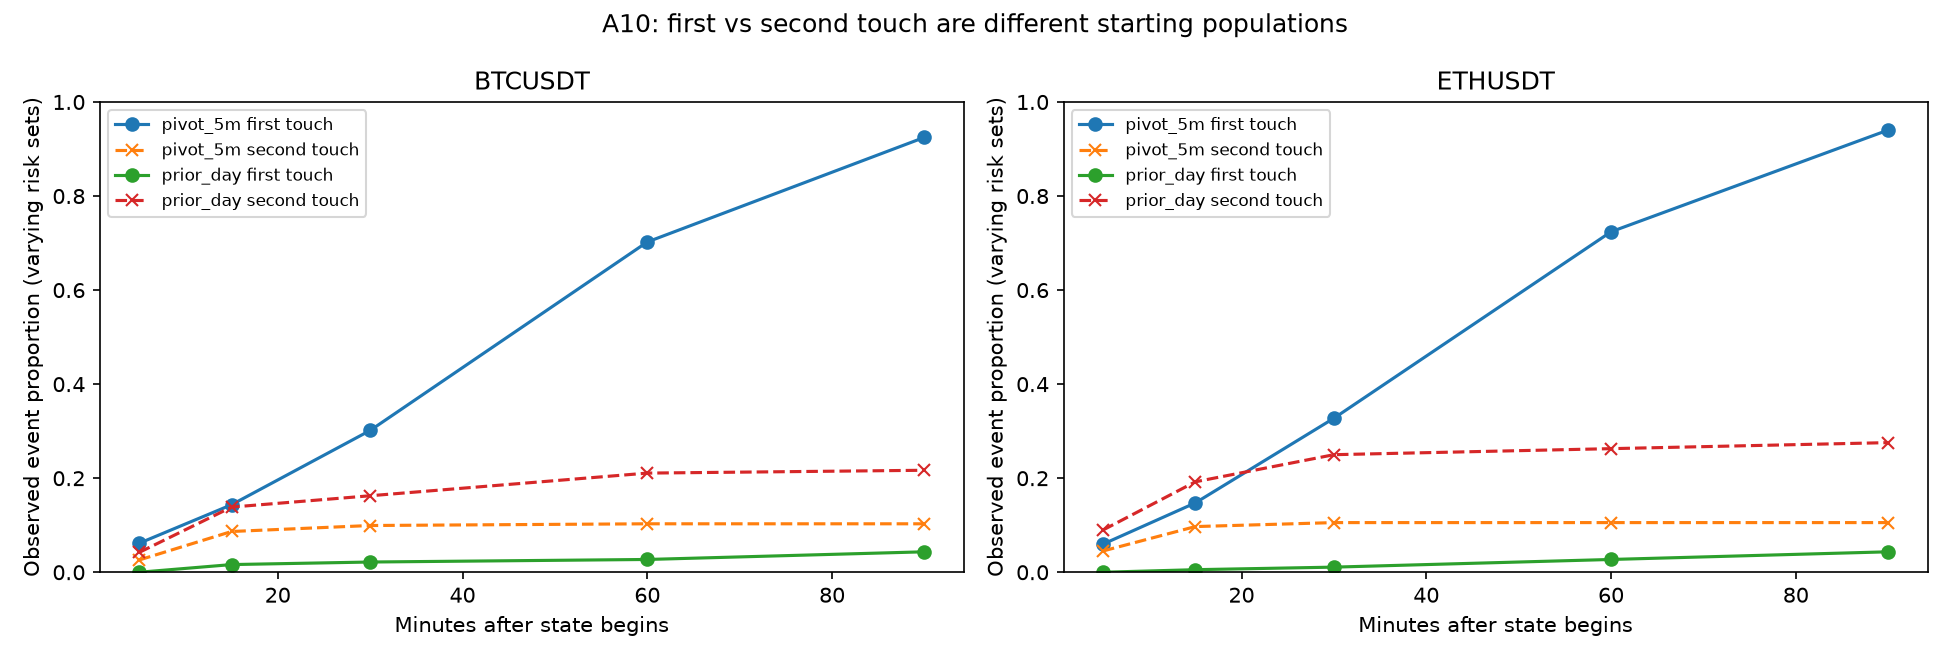

In [5]:
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image
fig,axes=plt.subplots(1,2,figsize=(13,4.4))
for ax,sym in zip(axes,('BTCUSDT','ETHUSDT')):
    q=groups[groups.symbol==sym]
    pivot=q[q.level_type=='pivot_5m'].groupby('classification').n.sum()
    prior=q[q.level_type=='prior_day'].groupby('classification').n.sum()
    labels=['NO_VALID_TOUCH','FIRST_TOUCH_NO_SIGNAL','SECOND_TOUCH_SIGNAL']
    ix=range(len(labels))
    ax.bar([i-0.18 for i in ix],[pivot.get(k,0) for k in labels],width=.35,label='5m pivots')
    ax.bar([i+0.18 for i in ix],[prior.get(k,0) for k in labels],width=.35,label='Prior day')
    ax.set_xticks(list(ix),['No touch','First only','Second signal'])
    ax.set(title=sym,ylabel='Observable reference episodes')
    ax.legend()
fig.suptitle('A10: original A02 reference-level denominator (not winner-only)')
fig.tight_layout();fig.savefig(OUT/'10_episode_classes.png',dpi=150);plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(13,4.4))
for ax,sym in zip(axes,('BTCUSDT','ETHUSDT')):
    for family in ('pivot_5m','prior_day'):
        a=first[(first.symbol==sym)&(first.level_type==family)].groupby('horizon_min').agg(
            touch=('n_first_touch_by_h','sum'),assess=('n_first_touch_known','sum')).reset_index()
        b=second[(second.symbol==sym)&(second.level_type==family)].groupby('horizon_min').agg(
            touch=('n_second_by_h','sum'),assess=('n_assessable','sum')).reset_index()
        if len(a):ax.plot(a.horizon_min,a.touch/a.assess.replace(0,float('nan')),marker='o',label=family+' first touch')
        if len(b):ax.plot(b.horizon_min,b.touch/b.assess.replace(0,float('nan')),marker='x',linestyle='--',label=family+' second touch')
    ax.set(title=sym,xlabel='Minutes after state begins',ylabel='Observed event proportion (varying risk sets)',ylim=(0,1))
    ax.legend(fontsize=8)
fig.suptitle('A10: first vs second touch are different starting populations')
fig.tight_layout();fig.savefig(OUT/'10_encounter_incidence.png',dpi=150);plt.close(fig)
for filename in ('10_episode_classes.png','10_encounter_incidence.png'):
    display(Image(filename=str(OUT/filename)))


## 5. Interpretation and next test

Original A02 settings and historical paths were already inspected. All rates here are **descriptive**, and touch detection may be mechanically favored by its own construction. The next valid comparison is an availability-time risk-set study that matches pivot/prior-day, symbol, side, contemporaneous volatility and reference age, then evaluates newly unseen days. Do not use a future second touch, eventual target, or final reference lifetime as a predictor at level availability. Historical naked percentage differences do **not** demonstrate trading profitability.
